In [25]:
#Importing Packages
import torch
import torch.nn as nn
import numpy as np
from torch.autograd import Variable
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [ ]:
#Defining the Neural Network model
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.hidden_layer1 = nn.Linear(2,20)
        self.hidden_layer2 = nn.Linear(20,30)
        self.hidden_layer3 = nn.Linear(30,40)
        self.hidden_layer4 = nn.Linear(40,30)
        self.hidden_layer5 = nn.Linear(30,20)
        self.output_layer = nn.Linear(20,1)
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_normal_(m.weight, gain=nn.init.calculate_gain('tanh'))
            nn.init.zeros_(m.bias)


    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        layer1_out = torch.tanh(self.hidden_layer1(inputs))
        layer2_out = torch.tanh(self.hidden_layer2(layer1_out))
        layer3_out = torch.tanh(self.hidden_layer3(layer2_out))
        layer4_out = torch.tanh(self.hidden_layer4(layer3_out))
        layer5_out = torch.tanh(self.hidden_layer5(layer4_out))
        output = self.output_layer(layer5_out)
        return output

In [ ]:
#Creating Net object
net = Net()
optimizer = torch.optim.Adam(net.parameters(), lr=0.005)

In [28]:
#Defining 1D Heat variables
a = 0.1 #Constant from 1D heat PDE
L = 1 # Length of bar in meters
M = 1 # Max time value in seconds

def f(x, t, net):
    t.requires_grad_(True)
    u = net(x, t) # the dependent variable u is given by the network based on independent variables x,t
    u_t = torch.autograd.grad(u.sum(), t, create_graph=True, retain_graph=True)[0]
    u_x = torch.autograd.grad(u.sum(), x, create_graph=True, retain_graph=True)[0]
    u_xx = torch.autograd.grad(u_x.sum(), x, create_graph=True, retain_graph=True)[0]
    pde = a*u_xx - u_t
    return pde

In [29]:
#Training Neural Network
loss_fn  = nn.MSELoss()
iterations = 20000
loss_pts = []

for epoch in range(iterations):
    optimizer.zero_grad() # to make the gradients zero

    #Physics loss
    x = (torch.rand(2000, 1) * L).requires_grad_(True).to(device)
    t = (torch.rand(2000, 1) * M).requires_grad_(True).to(device)

    u = f(x, t, net)

    loss_goal = torch.zeros((len(u),1)).float()

    p_loss = loss_fn(u, loss_goal)

    #Initial Condition loss

    t_i = torch.zeros((75,1)).float().requires_grad_(True).to(device)
    x_i = (torch.rand(75, 1) * L).requires_grad_(True).to(device)
    u_ic = net(x_i, t_i)
    loss_goal = torch.sin(np.pi*x_i)

    ic_loss = loss_fn(u_ic, loss_goal)

    #Boundary Condition loss
    t_bc = (torch.rand(100, 1) * M).requires_grad_(True).to(device)
    x0_bc = torch.zeros((50,1)).float().requires_grad_(True).to(device)
    xL_bc = torch.full((50,1), L).float().requires_grad_(True).to(device)
    x_bc = torch.cat([x0_bc, xL_bc], 0)
    u_bc = net(x_bc, t_bc)

    u_x_bc = torch.autograd.grad(u_bc, x_bc, create_graph=True, grad_outputs=torch.ones_like(u_bc), retain_graph=True)[0]
    loss_goal = torch.zeros((100,1)).float()

    #loss_goal = x_bc

    bc_loss = loss_fn(u_x_bc, loss_goal)

    loss = p_loss + 125*ic_loss + 20*bc_loss

    loss.backward()
    optimizer.step()

    #if epoch % 3750 == 0 and t_increase < 4:
    #    t_max += 0.25
    #    t_increase += 1

    if epoch % 20 == 0:
        loss_pts.append(loss.item())

    if epoch % 100 == 0:
        with torch.autograd.no_grad():
            print(epoch,"Traning Loss:",loss.item())


0 Traning Loss: 323.3349304199219
100 Traning Loss: 3.3070144653320312
200 Traning Loss: 1.943904161453247
300 Traning Loss: 0.8470416069030762
400 Traning Loss: 0.27618616819381714
500 Traning Loss: 0.26481810212135315
600 Traning Loss: 0.28603607416152954
700 Traning Loss: 0.1576026976108551
800 Traning Loss: 0.3859502971172333
900 Traning Loss: 0.1848704218864441
1000 Traning Loss: 0.17039981484413147
1100 Traning Loss: 0.22015784680843353
1200 Traning Loss: 0.11927420645952225
1300 Traning Loss: 0.19347748160362244
1400 Traning Loss: 0.13044658303260803
1500 Traning Loss: 0.1842345893383026
1600 Traning Loss: 1.3155043125152588
1700 Traning Loss: 0.12354600429534912
1800 Traning Loss: 0.2838386297225952
1900 Traning Loss: 0.12110322713851929
2000 Traning Loss: 0.11253582686185837
2100 Traning Loss: 0.10970406979322433
2200 Traning Loss: 0.22259077429771423
2300 Traning Loss: 0.1699388325214386
2400 Traning Loss: 0.12053179740905762
2500 Traning Loss: 0.1090848296880722
2600 Traning

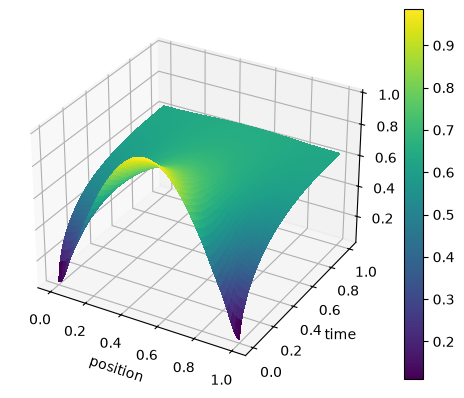

In [30]:
#Plotting results
x_test = torch.linspace(0, 1, 100).requires_grad_(True)
t_test = torch.linspace(0, 1, 100).requires_grad_(True)

X, T = torch.meshgrid(x_test, t_test, indexing='ij')  # each shape [50, 50]

# Flatten and stack into a single [N, 2] tensor of (x, t) pairs
x_flat = X.reshape(-1, 1)
t_flat = T.reshape(-1, 1)
u_test = net(x_flat, t_flat)

u_test = u_test.reshape(X.shape)

#Making torch tensors into usable numpy objects
X = X.detach().numpy()
T = T.detach().numpy()
u_test = u_test.detach().cpu().numpy()

#Making plots
#fig, axes = plt.subplots(1, 2, figsize=(12, 5), projection='3d') 
#ax1, ax2 = axes

fig = plt.figure()
ax1 = fig.add_subplot(projection='3d')

surface = ax1.plot_surface(X, T, u_test, cmap='viridis', linewidth=0, antialiased=False)
ax1.set_xlabel('position')
ax1.set_ylabel('time')

fig.colorbar(surface)

plt.show()